**Tarea 5: TSP de 15 ciudades mediante Templado Simulado**

Se sigue la tarea de la lámina 32 de la presentación 8. Cada ruta es una
permutación de 15 ciudades y cada vecina se obtiene intercambiando dos
posiciones distintas elegidas al azar. Se busca minimizar la distancia
total y regresar a la ciudad inicial.

El notebook conserva una ejecución completa. En Colab se puede repetir
con **Entorno de ejecución → Ejecutar todas**. Las coordenadas están
incluidas; las ciudades son un ejemplo sintético reproducible, con
distancias en unidades del plano.

In [1]:
import math
import random
import time
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SALIDA = Path('resultados_tsp')
SALIDA.mkdir(exist_ok=True)

La presentación no establece ciudades ni distancias concretas. Se
eligieron 15 puntos distintos generados con semilla 42 y se conservan
explícitamente para repetir la misma instancia. No representan kilómetros
entre municipios reales. La semilla del recorrido principal será 0.

In [2]:
coordenadas = np.array([[9, 78], [66, 44], [43, 86], [8, 70], [20, 9], [53, 98], [74, 76], [72, 79], [51, 12], [84, 45], [50, 37], [18, 93], [78, 65], [40, 83], [55, 44]], dtype=float)
ciudades = [f'C{i+1:02d}' for i in range(len(coordenadas))]
tabla_ciudades = pd.DataFrame(coordenadas.astype(int), columns=['x', 'y'])
tabla_ciudades.insert(0, 'ciudad', ciudades)
display(tabla_ciudades)
tabla_ciudades.to_csv(SALIDA / 'ciudades.csv', index=False)

,ciudad,x,y
0,C01,9,78
1,C02,66,44
2,C03,43,86
3,C04,8,70
4,C05,20,9
5,C06,53,98
6,C07,74,76
7,C08,72,79
8,C09,51,12
9,C10,84,45


La distancia entre dos ciudades es euclidiana:
$d(i,j)=\sqrt{(x_i-x_j)^2+(y_i-y_j)^2}$.
Para una ruta $v$, se suman sus 15 aristas, incluida la última hacia
la primera. La función `vecino_intercambio` copia `vc` y cambia sólo dos
posiciones para producir `vn`. Hay $\binom{15}{2}=105$ intercambios posibles.
Los índices internos van de 0 a 14; las etiquetas visibles son C01 a C15.

In [3]:
def matriz_distancias(coordenadas):
    puntos = np.asarray(coordenadas, dtype=float)
    diferencias = puntos[:, None, :] - puntos[None, :, :]
    return np.sqrt(np.sum(diferencias ** 2, axis=2))


def longitud(ruta, distancias):
    """Longitud del ciclo: incluye la vuelta de la última ciudad a la primera."""
    return sum(distancias[a][b] for a, b in zip(ruta, ruta[1:] + ruta[:1]))


def vecino_intercambio(vc, generador):
    """Elegir dos posiciones distintas; el vecino conserva las 15 ciudades."""
    i, j = generador.sample(range(len(vc)), 2)
    vn = vc.copy()
    vn[i], vn[j] = vn[j], vn[i]
    return vn, i, j

D = matriz_distancias(coordenadas)
assert D.shape == (15, 15) and np.allclose(D, D.T)
pd.DataFrame(D, index=ciudades, columns=ciudades).to_csv(SALIDA / 'distancias.csv')

La diferencia para **minimizar** es $\Delta=L(v_n)-L(v_c)$.
Se combinan la logística de las láminas 27–29 y el pseudocódigo de la 30:
si $\Delta<0$, la mejora se acepta siempre. En otro caso se acepta cuando
$u<p$, con $u$ uniforme entre 0 y 1, y
$$p=\frac{1}{1+e^{\Delta/T}}.$$

Con $\Delta=0$, $p=0.5$. Para una ruta peor, $\Delta>0$ y $p<0.5$;
al bajar la temperatura disminuye esa aceptación. Por ejemplo, cambiar
107 por 120 con $T=10$ da $p\approx0.214165$.
La implementación usa la expresión equivalente
$a=e^{-\Delta/T}$, $p=a/(1+a)$ para evitar desbordamientos numéricos.

In [4]:
def probabilidad_aceptar(delta, temperatura):
    """Mejoras estrictas: 1. Resto: logística de clase, para minimización."""
    if temperatura <= 0:
        raise ValueError('La temperatura debe ser positiva.')
    if delta < 0:
        return 1.0
    # Equivale a 1/(1+exp(delta/T)), evitando desbordar el exponencial.
    z = math.exp(-delta / temperatura)
    return z / (1.0 + z)

assert probabilidad_aceptar(-13, 10) == 1.0
assert probabilidad_aceptar(0, 10) == 0.5
print('p para empeorar de 107 a 120, T=10:', probabilidad_aceptar(13, 10))

p para empeorar de 107 a 120, T=10: 0.2141650169574414


Se comienza con T = 100, se proponen 100 intercambios por temperatura y
luego se enfría un 1 %: T nueva = 0.99 × T. El proceso termina cuando
T < 0.01. Se guarda la mejor ruta por separado de la ruta actual:
aceptar temporalmente un empeoramiento permite explorar sin perder
la mejor solución ya encontrada. No se utiliza el óptimo de referencia
para decidir vecinos, aceptar propuestas o detener la búsqueda.

In [5]:
def templado_simulado(distancias, semilla=0, t_inicial=100.0, t_minima=0.01,
                     enfriamiento=0.99, vecinos_por_temperatura=100):
    if not (0 < t_minima < t_inicial and 0 < enfriamiento < 1):
        raise ValueError('Se requiere 0 < Tmin < T0 y 0 < alpha < 1.')
    if vecinos_por_temperatura < 1:
        raise ValueError('Se requiere al menos un vecino por temperatura.')
    d = np.asarray(distancias, dtype=float).tolist()
    n = len(d)
    if n < 2 or any(len(fila) != n for fila in d):
        raise ValueError('La matriz debe ser cuadrada, con al menos dos ciudades.')
    rng = random.Random(semilla)
    vc = list(range(n))
    rng.shuffle(vc)
    ruta_inicial = vc.copy()
    costo_actual = longitud(vc, d)
    costo_inicial = costo_actual
    mejor_ruta, mejor_costo = vc.copy(), costo_actual
    temperatura = t_inicial
    propuestas = aceptadas = empeoramientos = mejoras = empates = 0
    nivel = 0
    historial = [{
        'nivel': 0, 'iteracion': 0, 'temperatura': temperatura,
        'costo_actual': costo_actual, 'mejor_costo': mejor_costo,
        'aceptados_nivel': 0, 'empeoramientos_aceptados_nivel': 0,
    }]
    ejemplo_intercambio = None
    inicio = time.perf_counter()
    while temperatura >= t_minima:
        aceptados_nivel = peores_nivel = 0
        for _ in range(vecinos_por_temperatura):
            vn, i, j = vecino_intercambio(vc, rng)
            costo_nuevo = longitud(vn, d)
            delta = costo_nuevo - costo_actual
            p = probabilidad_aceptar(delta, temperatura)
            # El azar se consulta sólo cuando no hay una mejora estricta.
            u = None if delta < 0 else rng.random()
            aceptar = delta < 0 or u < p
            propuestas += 1
            if ejemplo_intercambio is None:
                ejemplo_intercambio = {
                    'vc': vc.copy(), 'vn': vn.copy(), 'posiciones_base0': [i, j],
                    'costo_vc': costo_actual, 'costo_vn': costo_nuevo,
                    'delta': delta, 'temperatura': temperatura, 'p': p,
                    'u': u, 'aceptado': aceptar,
                }
            if aceptar:
                vc, costo_actual = vn, costo_nuevo
                aceptadas += 1
                aceptados_nivel += 1
                if delta > 0:
                    empeoramientos += 1
                    peores_nivel += 1
                elif delta < 0:
                    mejoras += 1
                else:
                    empates += 1
                if costo_actual < mejor_costo:
                    mejor_ruta, mejor_costo = vc.copy(), costo_actual
        nivel += 1
        historial.append({
            'nivel': nivel, 'iteracion': propuestas, 'temperatura': temperatura,
            'costo_actual': costo_actual, 'mejor_costo': mejor_costo,
            'aceptados_nivel': aceptados_nivel,
            'empeoramientos_aceptados_nivel': peores_nivel,
        })
        temperatura *= enfriamiento
    segundos = time.perf_counter() - inicio
    assert sorted(mejor_ruta) == list(range(n))
    assert math.isclose(longitud(mejor_ruta, d), mejor_costo, abs_tol=1e-10)
    assert mejor_costo <= costo_inicial
    assert all(b['mejor_costo'] <= a['mejor_costo']
               for a, b in zip(historial, historial[1:]))
    return {
        'semilla': semilla, 'ruta_inicial': ruta_inicial, 'costo_inicial': costo_inicial,
        'mejor_ruta': mejor_ruta, 'mejor_costo': mejor_costo,
        'ruta_final': vc.copy(), 'costo_final': costo_actual,
        'propuestas': propuestas, 'aceptadas': aceptadas,
        'empeoramientos_aceptados': empeoramientos,
        'mejoras_aceptadas': mejoras, 'empates_aceptados': empates,
        'niveles': nivel, 'temperatura_final': temperatura,
        'segundos': segundos, 'historial': historial,
        'ejemplo_intercambio': ejemplo_intercambio,
    }

Ejecutamos 20 corridas con semillas 0 a 19 y el mismo calendario. La
corrida principal es la semilla 0, fijada antes de observar resultados.
Los contadores comprueban que se aceptaron rutas peores durante la búsqueda.

In [6]:
corridas = []
for semilla in range(20):
    corrida = templado_simulado(D, semilla=semilla)
    corridas.append(corrida)
    print(f'Semilla {semilla:02d}: {corrida["mejor_costo"]:.6f}')

principal = corridas[0]
mejora = 100 * (principal['costo_inicial'] - principal['mejor_costo']) / principal['costo_inicial']
display(pd.DataFrame([{
    'Semilla': 0,
    'Distancia inicial': principal['costo_inicial'],
    'Mejor distancia': principal['mejor_costo'],
    'Reducción (%)': mejora,
    'Vecinos propuestos': principal['propuestas'],
    'Empeoramientos aceptados': principal['empeoramientos_aceptados'],
}]).round(6))

Semilla 00: 288.609288


Semilla 01: 288.609288


Semilla 02: 288.609288


Semilla 03: 288.609288


Semilla 04: 288.609288


Semilla 05: 288.609288


... (11 outputs left out)

Semilla 17: 288.609288


Semilla 18: 288.609288


Semilla 19: 288.609288


,Semilla,Distancia inicial,Mejor distancia,Reducción (%),Vecinos propuestos,Empeoramientos aceptados
0,0,631.08969,288.609288,54.268103,91700,3331


Primero se comparan la ruta inicial y la mejor ruta de la corrida
principal. Los segmentos cierran el ciclo. Después se muestra la
evolución de la distancia actual, de la mejor encontrada y de la
temperatura; el historial se registra cada 100 propuestas.

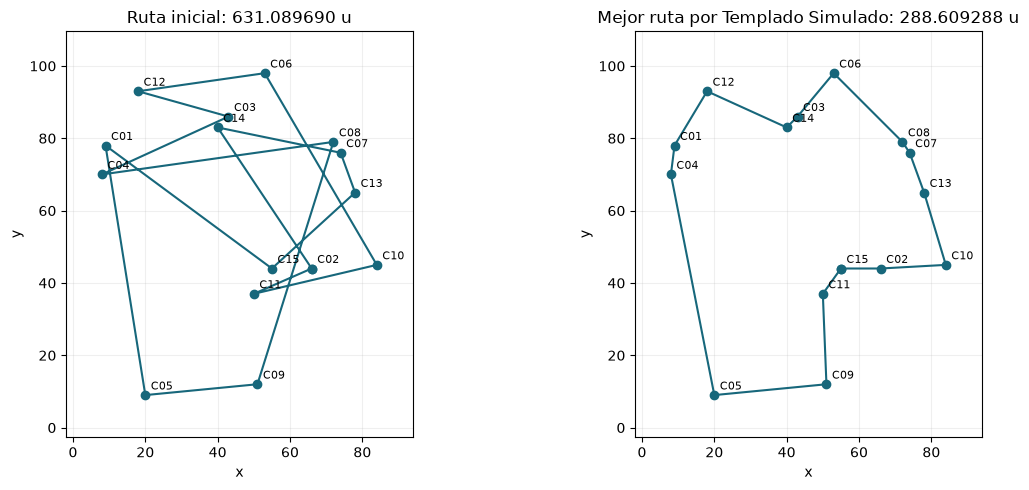

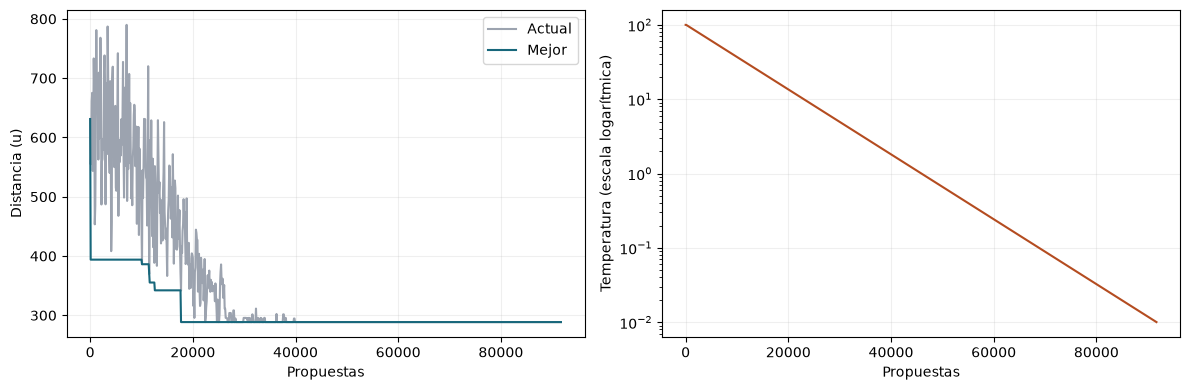

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
for eje, ruta, titulo in zip(ejes,
        [principal['ruta_inicial'], principal['mejor_ruta']],
        ['Ruta inicial', 'Mejor ruta por Templado Simulado']):
    ciclo = ruta + ruta[:1]
    eje.plot(coordenadas[ciclo, 0], coordenadas[ciclo, 1], '-o', color='#17677b')
    for nombre, (x, y) in zip(ciudades, coordenadas):
        eje.annotate(nombre, (x, y), xytext=(4, 4), textcoords='offset points', fontsize=8)
    eje.set_title(f'{titulo}: {longitud(ruta, D.tolist()):.6f} u')
    eje.set(xlabel='x', ylabel='y')
    eje.set_aspect('equal'); eje.margins(0.13); eje.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(SALIDA / 'rutas.png', dpi=150)
plt.show()

historial = pd.DataFrame(principal['historial'])
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(historial.iteracion, historial.costo_actual, color='#9ca3af', label='Actual')
ejes[0].plot(historial.iteracion, historial.mejor_costo, color='#17677b', label='Mejor')
ejes[0].set(xlabel='Propuestas', ylabel='Distancia (u)'); ejes[0].legend()
ejes[1].semilogy(historial.iteracion, historial.temperatura, color='#b44c20')
ejes[1].set(xlabel='Propuestas', ylabel='Temperatura (escala logarítmica)')
for eje in ejes:
    eje.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(SALIDA / 'convergencia.png', dpi=150)
plt.show()
historial.to_csv(SALIDA / 'historial_semilla0.csv', index=False)

Como comprobación adicional, calculamos el óptimo de esta instancia con
programación dinámica Held–Karp. Este cálculo se realiza después del
templado y no forma parte de su búsqueda. La celda plegada contiene el
método exacto; se contrasta con las 120 permutaciones de una subinstancia
de seis ciudades antes de usarlo con las quince.

In [8]:
# @title Comprobación exacta adicional: Held–Karp
from array import array
from itertools import permutations

def costo_ciclo(ruta, distancias):
    """Admite una permutación o su representación con el origen repetido al final."""
    if len(ruta) == 0:
        raise ValueError('La ruta no puede estar vacía.')
    nodos = list(ruta)
    if len(nodos) > 1 and nodos[-1] == nodos[0]:
        nodos.pop()
    return math.fsum(distancias[nodos[k]][nodos[(k + 1) % len(nodos)]]
                     for k in range(len(nodos)))


def canonicalizar(ruta):
    """Ancla en 0 y elige una orientación estable para un ciclo simétrico."""
    base = list(ruta)
    if len(base) > 1 and base[0] == base[-1]:
        base.pop()
    origen = base.index(0)
    base = base[origen:] + base[:origen]
    inversa = [0] + list(reversed(base[1:]))
    elegida = min(base, inversa)
    return elegida + [0]


def held_karp(distancias):
    """Resuelve exactamente el ciclo Hamiltoniano mínimo, anclando el nodo 0.

    dp[S,j] es el menor costo desde 0 que visita exactamente S y termina en j.
    S representa un subconjunto de las ciudades 1,...,n-1.
    La recurrencia considera todos los predecesores de j dentro de S.
    Tiempo O(n² 2^n); memoria O(n 2^n), incluyendo recuperación de la ruta.
    """
    iniciado = time.perf_counter()
    n = len(distancias)
    if n == 0 or any(len(fila) != n for fila in distancias):
        raise ValueError('La matriz de distancias debe ser cuadrada y no vacía.')
    for i in range(n):
        for j in range(n):
            if not math.isfinite(distancias[i][j]) or distancias[i][j] < 0:
                raise ValueError('Las distancias deben ser finitas y no negativas.')
            if not math.isclose(distancias[i][j], distancias[j][i], abs_tol=1e-12):
                raise ValueError('Esta referencia espera un TSP simétrico.')
    if n == 1:
        return {'costo_optimo': 0.0, 'ruta_indices': [0, 0],
                'permutacion_indices': [0], 'subproblemas': 1,
                'transiciones': 0, 'tiempo_segundos': time.perf_counter() - iniciado}
    m = n - 1
    total_mascaras = 1 << m
    dp = array('d', [math.inf]) * (total_mascaras * m)
    padres = array('h', [-1]) * (total_mascaras * m)
    for j in range(m):
        dp[(1 << j) * m + j] = distancias[0][j + 1]
    subproblemas = m
    transiciones = 0
    for mascara in range(1, total_mascaras):
        finales = mascara
        while finales:
            bit_j = finales & -finales
            j = bit_j.bit_length() - 1
            anteriores = mascara ^ bit_j
            if anteriores:
                mejor = math.inf
                padre = -1
                candidatos = anteriores
                while candidatos:
                    bit_i = candidatos & -candidatos
                    i = bit_i.bit_length() - 1
                    valor = dp[anteriores * m + i] + distancias[i + 1][j + 1]
                    if valor < mejor:
                        mejor, padre = valor, i
                    transiciones += 1
                    candidatos ^= bit_i
                dp[mascara * m + j] = mejor
                padres[mascara * m + j] = padre
                subproblemas += 1
            finales ^= bit_j
    completa = total_mascaras - 1
    ultimo = min(range(m), key=lambda j: dp[completa * m + j] + distancias[j + 1][0])
    optimo_dp = dp[completa * m + ultimo] + distancias[ultimo + 1][0]
    retroceso = []
    mascara = completa
    j = ultimo
    while mascara:
        retroceso.append(j + 1)
        padre = padres[mascara * m + j]
        mascara ^= 1 << j
        j = padre
    ruta = canonicalizar([0] + list(reversed(retroceso)) + [0])
    assert len(ruta) == n + 1 and ruta[0] == ruta[-1] == 0
    assert sorted(ruta[:-1]) == list(range(n))
    costo = costo_ciclo(ruta, distancias)
    assert math.isclose(costo, optimo_dp, rel_tol=1e-12, abs_tol=1e-9)
    assert subproblemas == m * (1 << (m - 1))
    if m > 1:
        assert transiciones == m * (m - 1) * (1 << (m - 2))
    return {
        'costo_optimo': costo,
        'ruta_indices': ruta,
        'permutacion_indices': ruta[:-1],
        'subproblemas': subproblemas,
        'transiciones': transiciones,
        'tiempo_segundos': time.perf_counter() - iniciado,
    }


def verificar_con_fuerza_bruta(distancias):
    """Comparación independiente enumerando los 5! ciclos anclados de seis ciudades."""
    n = min(6, len(distancias))
    submatriz = [fila[:n] for fila in distancias[:n]]
    costos = ((costo_ciclo([0, *resto, 0], submatriz), [0, *resto, 0])
              for resto in permutations(range(1, n)))
    optimo_bruto, ruta_bruta = min(costos)
    exacto = held_karp(submatriz)
    assert math.isclose(exacto['costo_optimo'], optimo_bruto, rel_tol=1e-12, abs_tol=1e-10)
    assert math.isclose(costo_ciclo(ruta_bruta, submatriz), optimo_bruto, abs_tol=1e-10)
    return {
        'numero_ciudades': n,
        'permutaciones_comprobadas': math.factorial(n - 1),
        'costo_fuerza_bruta': optimo_bruto,
        'costo_held_karp': exacto['costo_optimo'],
        'coinciden': True,
        'ruta_fuerza_bruta_indices': canonicalizar(ruta_bruta),
        'ruta_held_karp_indices': exacto['ruta_indices'],
    }

In [9]:
comprobacion_6 = verificar_con_fuerza_bruta(D.tolist())
assert comprobacion_6['coinciden']
exacto = held_karp(D.tolist())
optimo = exacto['costo_optimo']
coinciden = [math.isclose(c['mejor_costo'], optimo, rel_tol=0, abs_tol=1e-8) for c in corridas]
resumen = pd.DataFrame([{
    'semilla': c['semilla'], 'costo_inicial': c['costo_inicial'],
    'mejor_costo': c['mejor_costo'],
    'brecha_porcentaje': max(0, c['mejor_costo'] - optimo) / optimo * 100,
} for c in corridas])
display(resumen.round(6))
ruta = canonicalizar(principal['mejor_ruta'])
print('Óptimo exacto:', f'{optimo:.12f}', 'unidades')
print('Coincidencias con el óptimo:', sum(coinciden), '/', len(corridas))
print('Mejor ciclo:', ' → '.join(ciudades[i] for i in ruta))
resumen.to_csv(SALIDA / 'corridas.csv', index=False)
(SALIDA / 'optimo_exacto.json').write_text(json.dumps(exacto, indent=2), encoding='utf-8')

,semilla,costo_inicial,mejor_costo,brecha_porcentaje
0,0,631.089690,288.609288,0.0
1,1,702.869002,288.609288,0.0
2,2,769.777984,288.609288,0.0
3,3,764.703254,288.609288,0.0
4,4,734.406867,288.609288,0.0
5,5,671.930629,288.609288,0.0
6,6,595.683425,288.609288,0.0
7,7,768.184947,288.609288,0.0
8,8,766.807891,288.609288,0.0
9,9,796.379293,288.609288,0.0


Óptimo exacto: 288.609288133079 unidades
Coincidencias con el óptimo: 20 / 20
Mejor ciclo: C01 → C04 → C05 → C09 → C11 → C15 → C02 → C10 → C13 → C07 → C08 → C06 → C03 → C14 → C12 → C01


415

La siguiente conclusión se obtiene de los resultados de esta ejecución.
Alcanzar el óptimo en esta instancia y estas semillas no garantiza que
el templado lo encuentre siempre con cualquier dato o configuración.

In [10]:
conclusion = (
    f'La corrida principal redujo la distancia de {principal["costo_inicial"]:.6f} '
    f'a {principal["mejor_costo"]:.6f} unidades ({mejora:.2f} %). '
    f'Se propusieron {principal["propuestas"]:,} intercambios y se aceptaron '
    f'{principal["empeoramientos_aceptados"]:,} empeoramientos durante la exploración. '
    f'{sum(coinciden)} de las {len(corridas)} corridas coincidieron con el óptimo '
    f'de referencia, con tolerancia absoluta de 1e-8 unidades.'
)
display(Markdown(conclusion))
(SALIDA / 'conclusion.txt').write_text(conclusion, encoding='utf-8')

La corrida principal redujo la distancia de 631.089690 a 288.609288 unidades (54.27 %). Se propusieron 91,700 intercambios y se aceptaron 3,331 empeoramientos durante la exploración. 20 de las 20 corridas coincidieron con el óptimo de referencia, con tolerancia absoluta de 1e-8 unidades.

288

Los archivos de `resultados_tsp` se pueden descargar desde **Archivos**
en Colab. La ruta conserva las 15 ciudades y cierra en su origen.

Fuentes: presentación 8 de la clase, láminas 27–32;
[regla de aceptación de MathWorks](https://www.mathworks.com/help/gads/how-simulated-annealing-works.html);
[Held y Karp: programación dinámica para secuenciación y TSP](https://research.ibm.com/publications/a-dynamic-programming-approach-to-sequencing-problems).